# Tutorial: clasificación de razas de mascotas con transfer learning

En este notebook construiremos, paso a paso, un clasificador de imágenes que reconoce **37 razas de perros y gatos** (dataset *Oxford-IIIT Pet*).

El flujo es el de cualquier proyecto de Computer Vision:

1. **Preparar el entorno** y comprobar la GPU.
2. **Explorar los datos** y entender sus clases.
3. **Preprocesar y aumentar** las imágenes.
4. **Crear los DataLoaders** (lotes de datos para la red).
5. **Construir el modelo** a partir de una red preentrenada.
6. **Entrenar** y seguir las curvas de aprendizaje.
7. **Evaluar** en datos que el modelo nunca vio.
8. **Predecir** sobre una imagen nueva.

> La lógica vive en `src/cv/`. Este notebook la importa y explica cada paso, así que no hay código duplicado: lo que ves aquí es lo mismo que ejecutan `python -m cv.train` y compañía.

## 0. ¿Qué es transfer learning?

Entrenar una red de visión desde cero necesita **millones** de imágenes y mucho cómputo. Pero las primeras capas de una red ya aprenden cosas universales (bordes, texturas, formas), así que podemos **reutilizarlas**:

- Tomamos una **ResNet18** entrenada en ImageNet (1.2 millones de imágenes, 1000 clases).
- **Congelamos** sus capas (no se actualizan).
- **Reemplazamos la última capa** por una de 37 salidas (una por raza) y solo esa capa aprende.

Resultado: un buen clasificador en pocos minutos y con pocos datos.

## 1. Preparación del entorno

Las rutas, hiperparámetros y semillas están en `configs/config.yaml`. Cargamos esa configuración y revisamos si PyTorch ve la GPU.

In [1]:
import torch
import matplotlib.pyplot as plt
from torchvision import datasets

from cv.config import ROOT, load_config
from cv.data import IMAGENET_MEAN, IMAGENET_STD, build_transforms, get_dataloaders
from cv.model import build_model, load_checkpoint
from cv.train import get_device, train
from cv.evaluate import evaluate
from cv.predict import predict_image

cfg = load_config()
device = get_device()

print("Dispositivo:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Configuración:", cfg["data"], cfg["train"], sep="\n")

Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU
Configuración:
{'root': 'data/raw', 'image_size': 224, 'val_split': 0.15, 'num_workers': 0}
{'epochs': 5, 'batch_size': 64, 'lr': 0.001, 'checkpoint': 'models/best.pt'}


## 2. Descarga y exploración del dataset

`get_dataloaders` descarga Oxford-IIIT Pet la primera vez (≈ 800 MB) y lo separa en:

- **train**: para aprender los pesos.
- **val**: para elegir el mejor modelo durante el entrenamiento.
- **test**: solo para la evaluación final.

Hay que mantener el test "guardado" hasta el final; si lo usáramos para decidir cosas, la métrica final sería optimista.

In [2]:
loaders = get_dataloaders(cfg)
classes = loaders["classes"]

print(f"Número de clases: {len(classes)}")
print(f"Train: {len(loaders['train'].dataset)} imágenes")
print(f"Val:   {len(loaders['val'].dataset)} imágenes")
print(f"Test:  {len(loaders['test'].dataset)} imágenes")
print("Primeras clases:", classes[:8])

Número de clases: 37
Train: 3128 imágenes
Val:   552 imágenes
Test:  3669 imágenes
Primeras clases: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay']


Veamos algunas imágenes **sin transformar** para tener una idea de los datos. Cargamos el dataset crudo (sin transformaciones) solo para visualizar.

In [3]:
raw = datasets.OxfordIIITPet(ROOT / cfg["data"]["root"], split="trainval",
                             target_types="category", download=False)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.flat, range(0, 800, 100)):
    img, label = raw[i]
    ax.imshow(img)
    ax.set_title(raw.classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

C:\Users\cnvas\AppData\Local\Temp\ipykernel_30228\3710296205.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 3. Preprocesamiento y data augmentation

Las redes esperan:

- Imágenes de un **tamaño fijo** (224×224 para ResNet).
- Valores normalizados con la **media y desviación de ImageNet**.

En **entrenamiento** además aplicamos *augmentation*: recortes, volteos y cambios de brillo aleatorios. Así el modelo ve variaciones de la misma foto y generaliza mejor. En **validación y test** solo redimensionamos y recortamos al centro, para que la evaluación sea determinista.

Abajo aplicamos la transformación de entrenamiento 4 veces a la misma imagen. Para mostrarla, deshacemos la normalización.

In [4]:
def denormalize(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

aug = build_transforms(cfg["data"]["image_size"], train=True)
img, _ = raw[0]

fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
axes[0].imshow(img)
axes[0].set_title("Original")
for ax in axes[1:]:
    ax.imshow(denormalize(aug(img)))
    ax.set_title("Augmentada")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

C:\Users\cnvas\AppData\Local\Temp\ipykernel_30228\3215217409.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 4. DataLoaders: cómo llegan los datos a la red

Un `DataLoader` agrupa imágenes en **lotes** (batches) y, en train, las mezcla en cada época. Los lotes tienen la forma `(batch, canales, alto, ancho)`.

In [5]:
x, y = next(iter(loaders["train"]))
print("Lote X:", tuple(x.shape), x.dtype)
print("Lote y:", tuple(y.shape), y.dtype, "| primeras etiquetas:", y[:5].tolist())

Lote X: (64, 3, 224, 224) torch.float32
Lote y: (64,) torch.int64 | primeras etiquetas: [4, 12, 27, 15, 33]


## 5. Construcción del modelo

`build_model` carga ResNet18 con pesos de ImageNet, congela el backbone y añade la nueva capa `fc`. Contamos los parámetros para confirmar que solo entrenaremos una fracción pequeña.

In [6]:
model = build_model(num_classes=len(classes), freeze_backbone=cfg["model"]["freeze_backbone"])

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Parámetros entrenables: {trainable:,} de {total:,} ({100 * trainable / total:.2f}%)")

Parámetros entrenables: 18,981 de 11,195,493 (0.17%)


## 6. Entrenamiento

Cada **época** recorre todo el set de train:

1. El modelo predice un lote.
2. La **función de pérdida** (*cross-entropy*) mide el error.
3. El **optimizador** (Adam) ajusta los pesos para reducirlo.

Al final de cada época medimos el rendimiento en **val** y guardamos el checkpoint solo si mejora. Usamos 3 épocas para que el notebook sea rápido; en `config.yaml` puedes cambiarlo.

> Ejecutar `uv run python -m cv.train` hace exactamente lo mismo desde la terminal.

In [7]:
history = train(epochs=3)

Dispositivo: cuda | clases: 37 | épocas: 3


  0%|          | 0/49 [00:00<?, ?it/s]

  2%|▏         | 1/49 [00:00<00:26,  1.81it/s]

  4%|▍         | 2/49 [00:00<00:19,  2.46it/s]

  6%|▌         | 3/49 [00:01<00:16,  2.87it/s]

...

 67%|██████▋   | 6/9 [00:01<00:00,  3.60it/s]

 78%|███████▊  | 7/9 [00:01<00:00,  3.65it/s]

 89%|████████▉ | 8/9 [00:02<00:00,  3.67it/s]

100%|██████████| 9/9 [00:02<00:00,  4.20it/s]

Época 3/3 | train loss 0.657 acc 0.883 | val loss 0.589 acc 0.864
Mejor val acc: 0.864 | checkpoint: models\best.pt


Las curvas nos dicen si el modelo aprende:

- Si **train** mejora pero **val** no → sobreajuste (*overfitting*).
- Si ambas mejoran juntas → vamos bien.

In [8]:
epochs = [h["epoch"] for h in history]
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

ax_loss.plot(epochs, [h["train_loss"] for h in history], marker="o", label="train")
ax_loss.plot(epochs, [h["val_loss"] for h in history], marker="o", label="val")
ax_loss.set_title("Pérdida (loss)")
ax_loss.set_xlabel("época")
ax_loss.legend()

ax_acc.plot(epochs, [h["train_acc"] for h in history], marker="o", label="train")
ax_acc.plot(epochs, [h["val_acc"] for h in history], marker="o", label="val")
ax_acc.set_title("Accuracy")
ax_acc.set_xlabel("época")
ax_acc.legend()

plt.tight_layout()
plt.show()

C:\Users\cnvas\AppData\Local\Temp\ipykernel_30228\1350780785.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 7. Evaluación en el conjunto de test

Ahora sí usamos el test, una única vez. `evaluate()` calcula:

- **Accuracy** global.
- **F1 macro** (promedio por clase; penaliza fallar en razas poco frecuentes).
- La **matriz de confusión**: qué razas se confunden entre sí.

In [9]:
metrics = evaluate(cfg)

Test accuracy: 0.842 | macro F1: 0.838
Guardado en K:\Data WorkSpace Krispy\CV\outputs


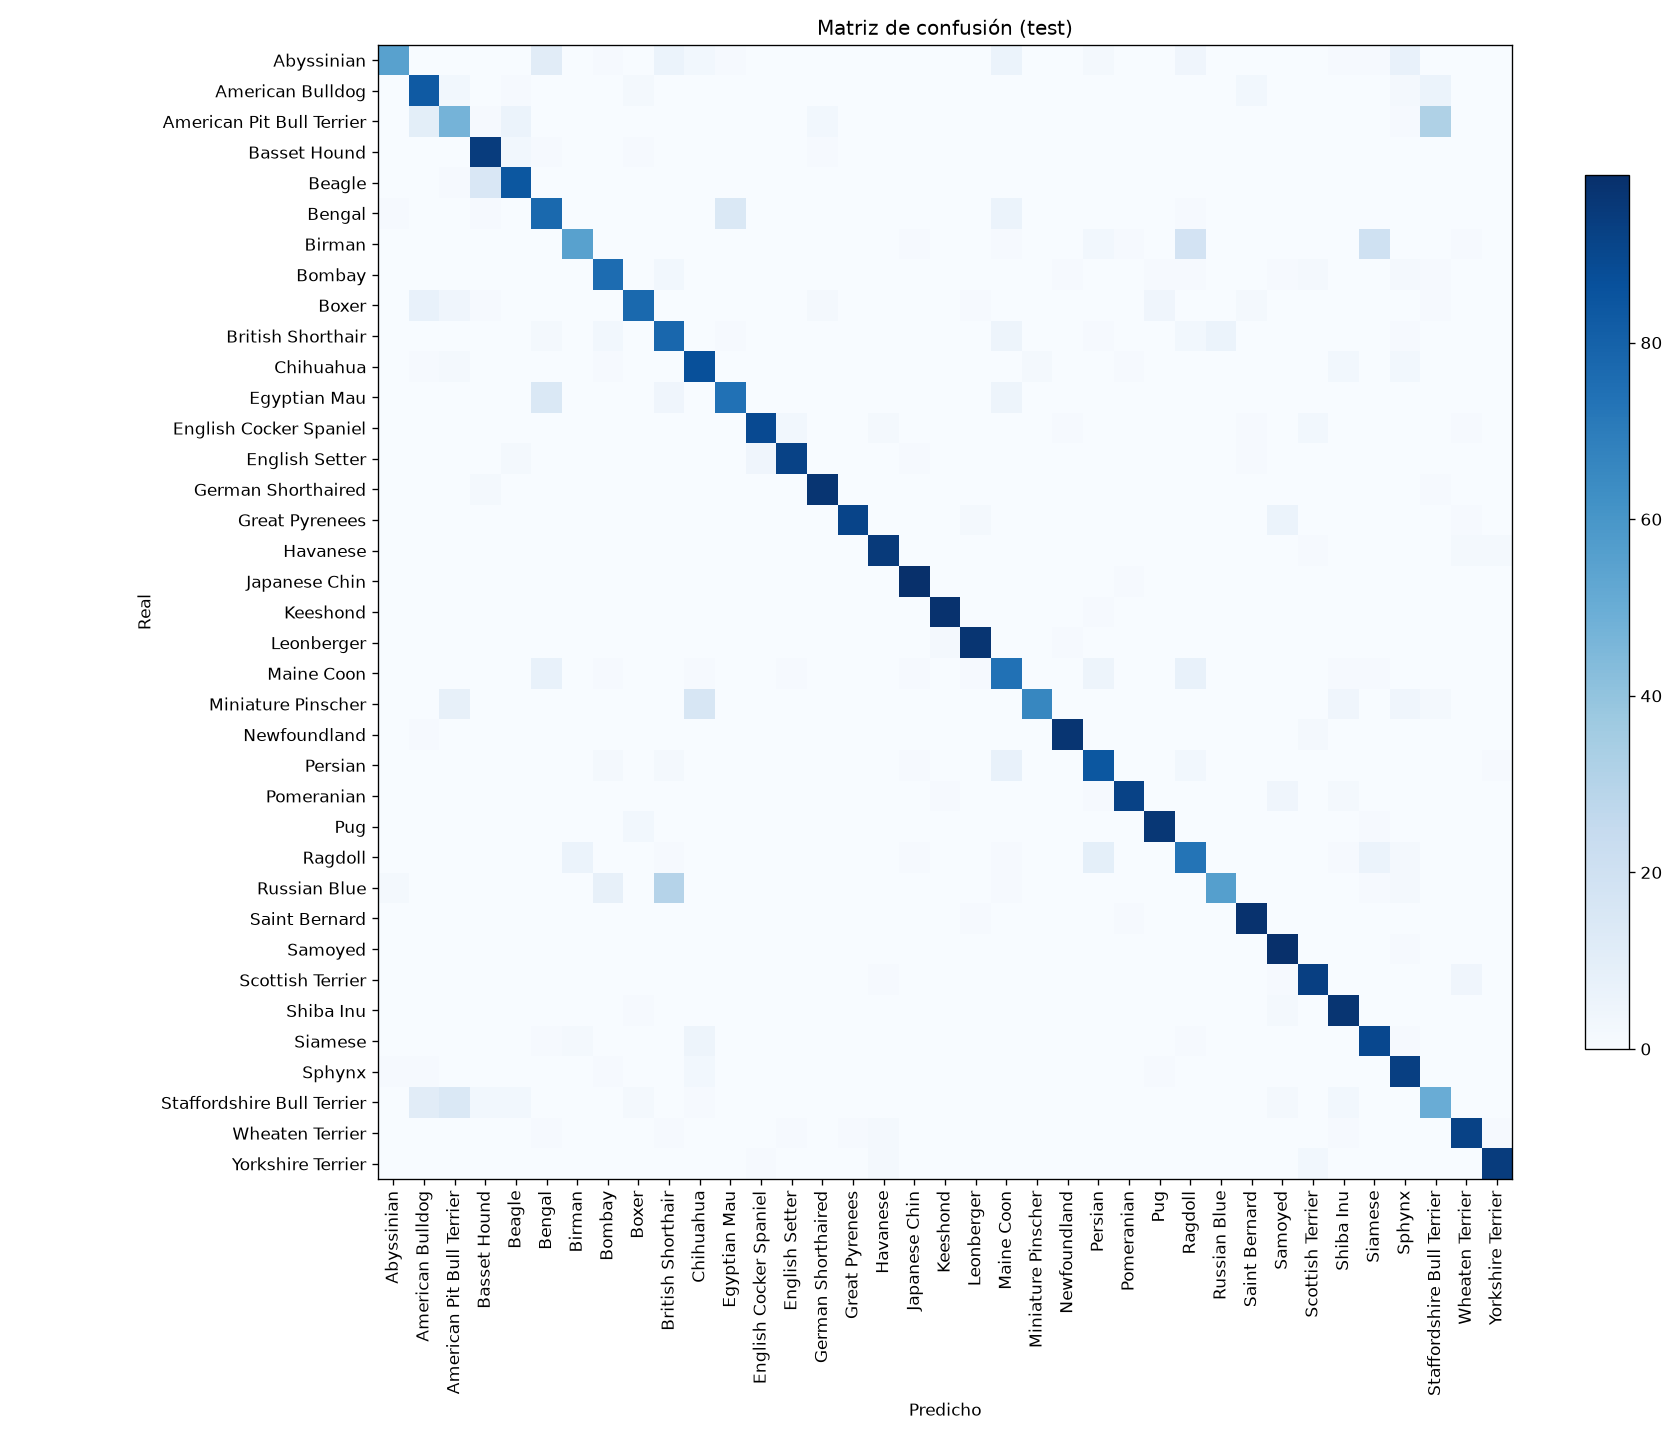

In [10]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / cfg["evaluate"]["output_dir"] / "confusion_matrix.png"), width=750))

Las razas con **menor F1** son las que más cuesta distinguir para el modelo:

In [11]:
worst = sorted(metrics["per_class"].items(), key=lambda kv: kv[1]["f1-score"])[:5]
for name, m in worst:
    print(f"{name:<25} F1={m['f1-score']:.2f}  precision={m['precision']:.2f}  recall={m['recall']:.2f}")

American Pit Bull Terrier F1=0.53  precision=0.59  recall=0.47
Staffordshire Bull Terrier F1=0.55  precision=0.54  recall=0.56
Birman                    F1=0.67  precision=0.87  recall=0.55
Russian Blue              F1=0.69  precision=0.90  recall=0.56
Ragdoll                   F1=0.69  precision=0.66  recall=0.73


## 8. Inferencia sobre una imagen nueva

Cargamos el mejor checkpoint y predecimos la raza de una imagen. Por defecto usamos una del dataset; **cambia `ruta_imagen` por una foto tuya** para probarlo.

In [12]:
model, ckpt = load_checkpoint(ROOT / cfg["train"]["checkpoint"], device)

ruta_imagen = sorted((ROOT / cfg["data"]["root"] / "oxford-iiit-pet" / "images").glob("*.jpg"))[500]
results = predict_image(ruta_imagen, model, ckpt["classes"], ckpt["image_size"], device, topk=3)

from PIL import Image as PILImage
plt.figure(figsize=(5, 5))
plt.imshow(PILImage.open(ruta_imagen).convert("RGB"))
plt.title(f"Top-1: {results[0][0]} ({results[0][1] * 100:.1f}%)")
plt.axis("off")
plt.show()

for name, p in results:
    print(f"{name:<25} {p * 100:5.1f}%")

Staffordshire Bull Terrier  26.5%
American Bulldog           23.0%
American Pit Bull Terrier  19.5%


C:\Users\cnvas\AppData\Local\Temp\ipykernel_30228\139994641.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 9. Siguientes pasos

Ya tienes un pipeline completo. Ideas para seguir:

- **Fine-tuning**: poner `freeze_backbone: false` (o descongelar solo `layer4`) y bajar el learning rate.
- **Más épocas** y un *scheduler* de learning rate (p. ej. `CosineAnnealingLR`).
- **Otro backbone**: cambiar `resnet18` por `efficientnet_b0` en `src/cv/model.py`.
- **Exportar** el modelo a ONNX para usarlo fuera de PyTorch.
- **Detección o segmentación**: mismo enfoque, pero con datasets y arquitecturas distintas.